# 8 · No split, no merge: the segmentation at different K

One Gaussian mixture on ALL movements (no direction split, no merging), on the paper model's features (shared PCA of the
signed absolute velocity + log duration, z-scored, same fit sample of 2000 movements / mouse; as
`nosplit_states.py`), for several K. Clusters are numbered by median peak speed and coloured as in
`fig_segmentation_wheel6` (one olive hue, lightness = vigor rank; they carry no direction).

1. per K: each cluster's median shape (members aligned so their first half goes +) and its peak / duration / jitter;
2. session snippets: for each session the same window drawn once per K, the wheel trace with every movement shaded by
   its cluster (as figure 1 panel f), so the segmentations can be compared movement by movement.

Nothing is saved.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
import sys, pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from joblib import Parallel, delayed
from sklearn.mixture import GaussianMixture
REPO = pathlib.Path.cwd().resolve()
while not (REPO / 'paper-individuality').exists() and REPO != REPO.parent:
    REPO = REPO.parent
PI = REPO / 'paper-individuality'
for _d in (PI, PI / 'segmentation', PI / 'figure_generation'):
    sys.path.insert(0, str(_d))
import paper_style as ps
import wheel_movement_clusters as wmc
import cartoon_segmentation_wheel as csw
ps.use('paper', dpi=110)

KS = [3, 4, 5, 6, 8, 10]
PAPER = wmc.load_model('proficient', 21)
coh = wmc.fit_cohort()
out = Parallel(n_jobs=12)(delayed(wmc.session_shapes)('proficient', m, e) for m, e in zip(coh.mouse, coh.eid))
ALL_S = {e: s for (s, _), e in zip(out, coh.eid)}
ALL_I = {e: i for (_, i), e in zip(out, coh.eid)}
S, info = wmc.sample(coh, ALL_S, ALL_I)
F = wmc._features(PAPER, S, info.duration)
print(f'fit sample {len(S):,} movements, {F.shape[1]} features')

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


fit sample 116,056 movements, 16 features


In [2]:
def palette(n):
    L = np.linspace(0.90, 0.48, n)                 # as cartoon_segmentation_wheel.wheel6_colours
    return [ps.oklch_to_hex(l, 0.075, csw.WHEEL6_HUE) for l in L]

def fit_k(k):
    gm = GaussianMixture(k, covariance_type='full', n_init=wmc.N_INIT, random_state=wmc.SEED).fit(F)
    raw = gm.predict(F)
    peak = pd.Series(info.peak.values).groupby(raw).median()
    rel = {int(r): i for i, r in enumerate(peak.sort_values().index)}     # cluster number by median peak
    return gm, rel
FITS = dict(zip(KS, Parallel(n_jobs=len(KS))(delayed(fit_k)(k) for k in KS)))
def predict(k, Sx, dur):
    gm, rel = FITS[k]
    return np.array([rel[r] for r in gm.predict(wmc._features(PAPER, Sx, dur))])
LAB = {k: predict(k, S, info.duration) for k in KS}
D1 = np.where(S[:, :wmc.NT // 2].sum(1) >= 0, 1, -1)                     # first-half direction
DESC = {k: pd.DataFrame({'share': np.bincount(LAB[k], minlength=k) / len(S),
                         'peak': [np.median(info.peak.values[LAB[k] == c]) for c in range(k)],
                         'duration': [np.median(info.duration.values[LAB[k] == c]) for c in range(k)],
                         'jitter': [np.median([wmc.reversals(a) for a in S[LAB[k] == c][:2000]]) for c in range(k)],
                         'CCW share': [np.mean(D1[LAB[k] == c] > 0) for c in range(k)]}).rename_axis('cluster')
        for k in KS}
COLS = {k: palette(k) for k in KS}
pd.concat(DESC, names=['K']).round(2)

/home/ines/miniconda3/envs/iblenv/lib/python3.10/site-packages/sklearn/mixture/_base.py:275: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


share  peak  duration  jitter  CCW share
K  cluster                                          
3  0         0.18  0.36      0.17     1.0       0.52
   1         0.35  1.83      0.56     1.0       0.51
   2         0.47  3.28      1.42     4.0       0.51
4  0         0.14  0.32      0.14     0.0       0.53
   1         0.20  1.04      0.39     1.0       0.51
   2         0.31  2.50      0.77     2.0       0.51
   3         0.36  3.43      1.63     5.0       0.51
5  0         0.11  0.29      0.12     0.0       0.54
   1         0.13  0.66      0.30     1.0       0.51
   2         0.20  1.86      0.55     1.0       0.51
   3         0.27  2.75      0.93     2.0       0.51
   4         0.29  3.53      1.79     5.0       0.50
6  0         0.10  0.29      0.12     0.0       0.54
   1         0.13  0.64      0.29     1.0       0.51
   2         0.19  1.80      0.53     1.0       0.51
   3         0.25  2.75      0.88     2.0       0.51
   4         0.16  2.97      1.80     6.0       0.51
   5         0.16  3.97      1.66     5.0       0.50
8  0         0.07  0.25      0.11     0.0       0.55
   1         0.10  0.46      0.21     1.0       0.50
   2         0.13  1.07      0.39     1.0       0.52
   3         0.16  2.14      0.61     2.0       0.51
   4         0.05  2.68      0.82     0.0       0.53
   5         0.20  2.88      0.98     3.0       0.51
   6         0.15  2.99      1.87     6.0       0.50
   7         0.14  4.07      1.78     5.0       0.50
10 0         0.06  0.24      0.10     0.0       0.55
   1         0.09  0.43      0.19     1.0       0.50
   2         0.12  0.88      0.36     1.0       0.51
   3         0.15  1.99      0.56     2.0       0.51
   4         0.07  2.28      1.02     2.0       0.51
   5         0.04  2.52      0.68     0.0       0.54
   6         0.14  2.93      0.86     3.0       0.52
   7         0.09  3.00      1.32     4.0       0.51
   8         0.11  3.04      2.12     7.0       0.50
   9         0.12  4.13      1.73     5.0       0.50

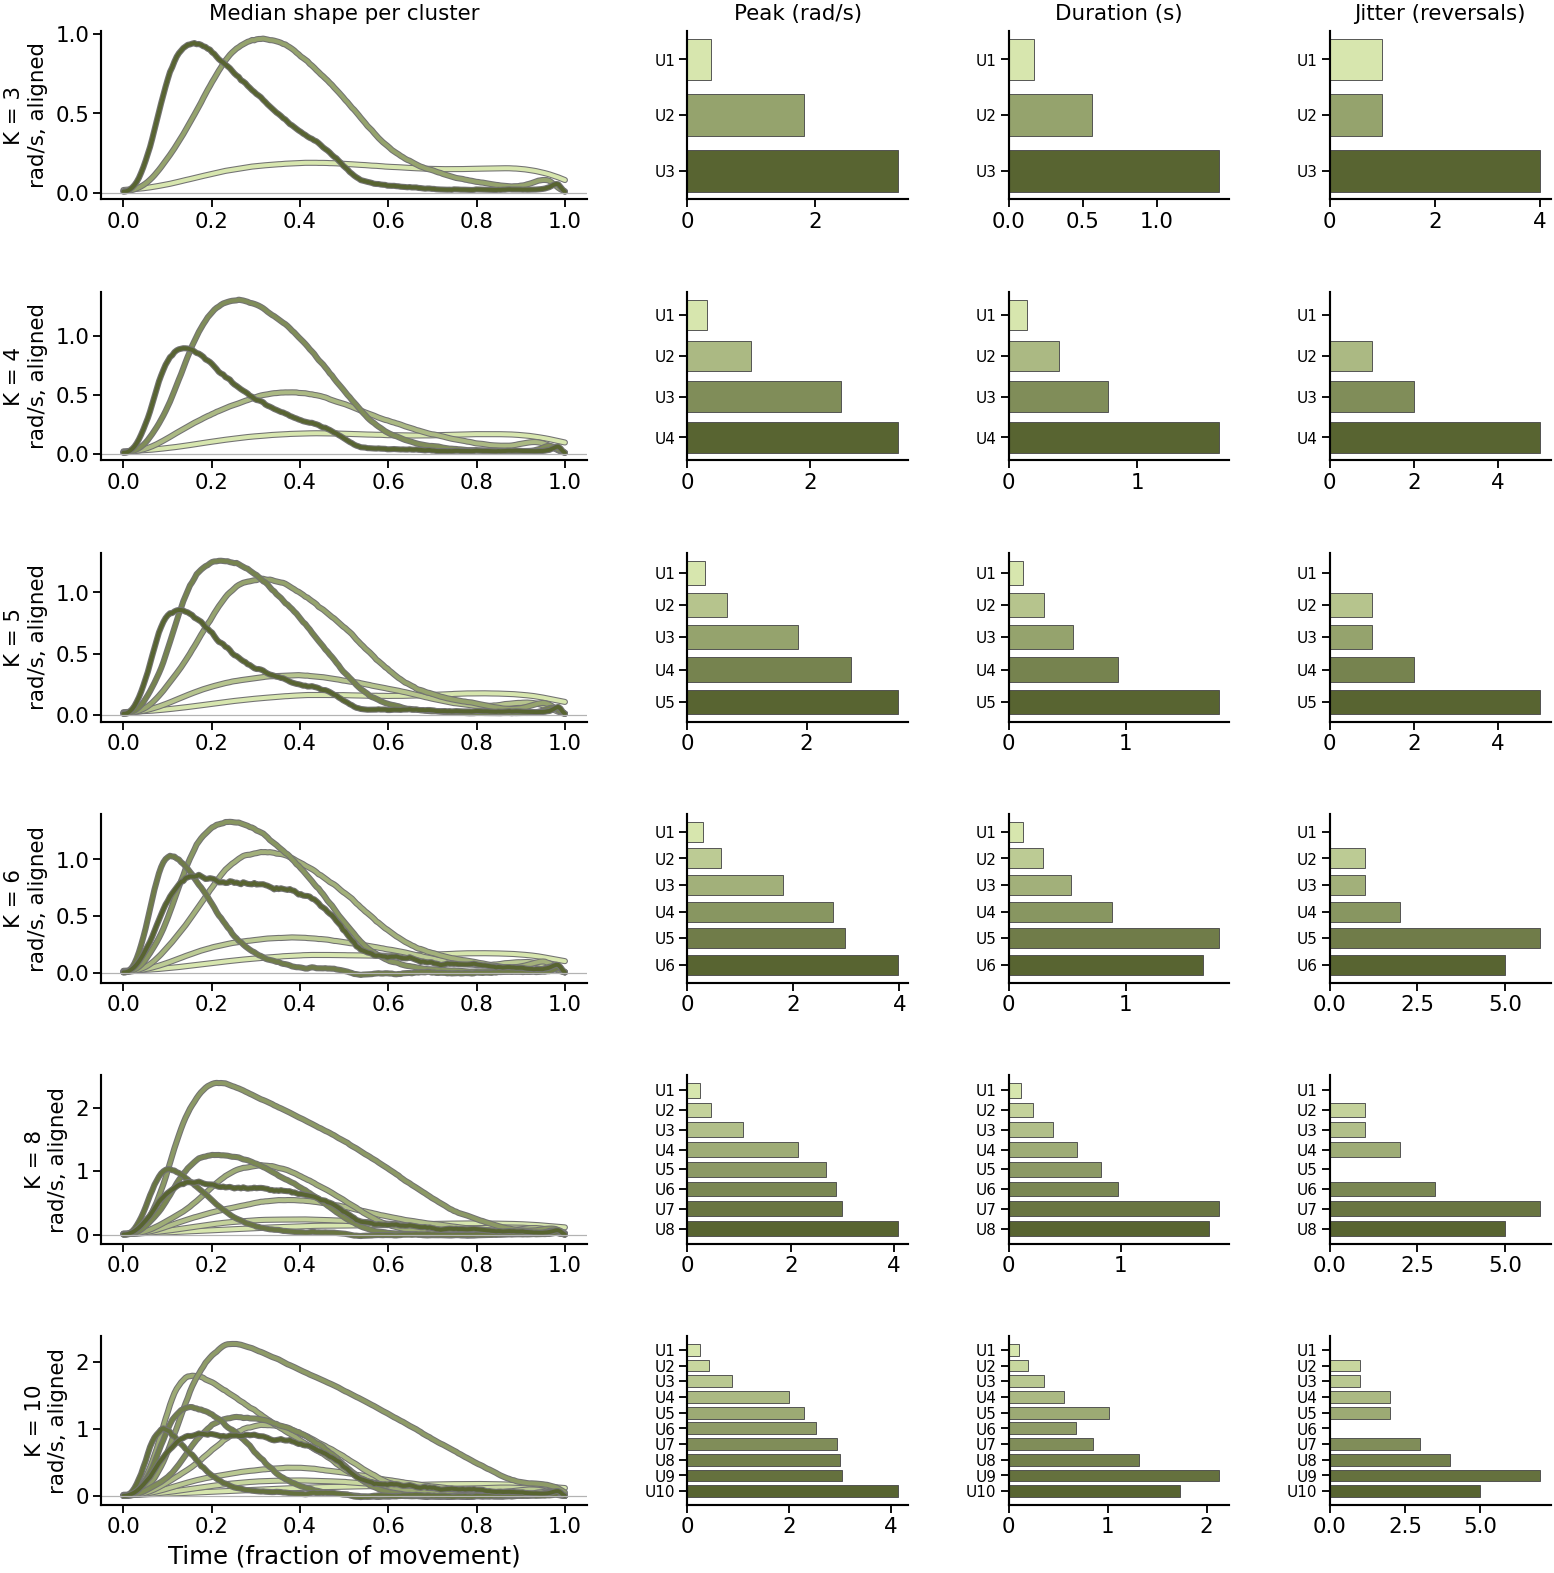

In [3]:
# per K: median shape of every cluster (members aligned: first half +), and peak / duration / jitter per cluster
x = np.linspace(0, 1, wmc.NT)
S_al = S * D1[:, None]
fig, axs = plt.subplots(len(KS), 4, figsize=(8.5, 1.45 * len(KS)), gridspec_kw=dict(width_ratios=[2.2, 1, 1, 1], hspace=0.55, wspace=0.35))
for r, k in enumerate(KS):
    ax = axs[r, 0]
    for c in range(k):
        ax.plot(x, np.median(S_al[LAB[k] == c], 0), color=COLS[k][c], lw=1.3,
                path_effects=[pe.Stroke(linewidth=2.0, foreground='0.45'), pe.Normal()])
    ax.axhline(0, color='0.7', lw=0.4); ax.set_ylabel(f'K = {k}\nrad/s, aligned', fontsize=7)
    for j, col in enumerate(['peak', 'duration', 'jitter']):
        a = axs[r, j + 1]
        a.barh(-np.arange(k), DESC[k][col], color=COLS[k], edgecolor='0.3', lw=0.3, height=0.75)
        a.set_yticks(-np.arange(k)); a.set_yticklabels([f'U{c + 1}' for c in range(k)], fontsize=5)
        if r == 0: a.set_title({'peak': 'Peak (rad/s)', 'duration': 'Duration (s)', 'jitter': 'Jitter (reversals)'}[col], fontsize=7)
axs[0, 0].set_title('Median shape per cluster', fontsize=7); axs[-1, 0].set_xlabel('Time (fraction of movement)')
plt.show()

## Session snippets: the same window segmented at every K
8 sessions (one per mouse), a 15 s window starting at a random trial. Per session one row per K: the wheel trace
(rad/s, CCW +) with every IBL movement shaded by its cluster, cluster number on top; dashed lines = stimulus on (blue)
and feedback (red).

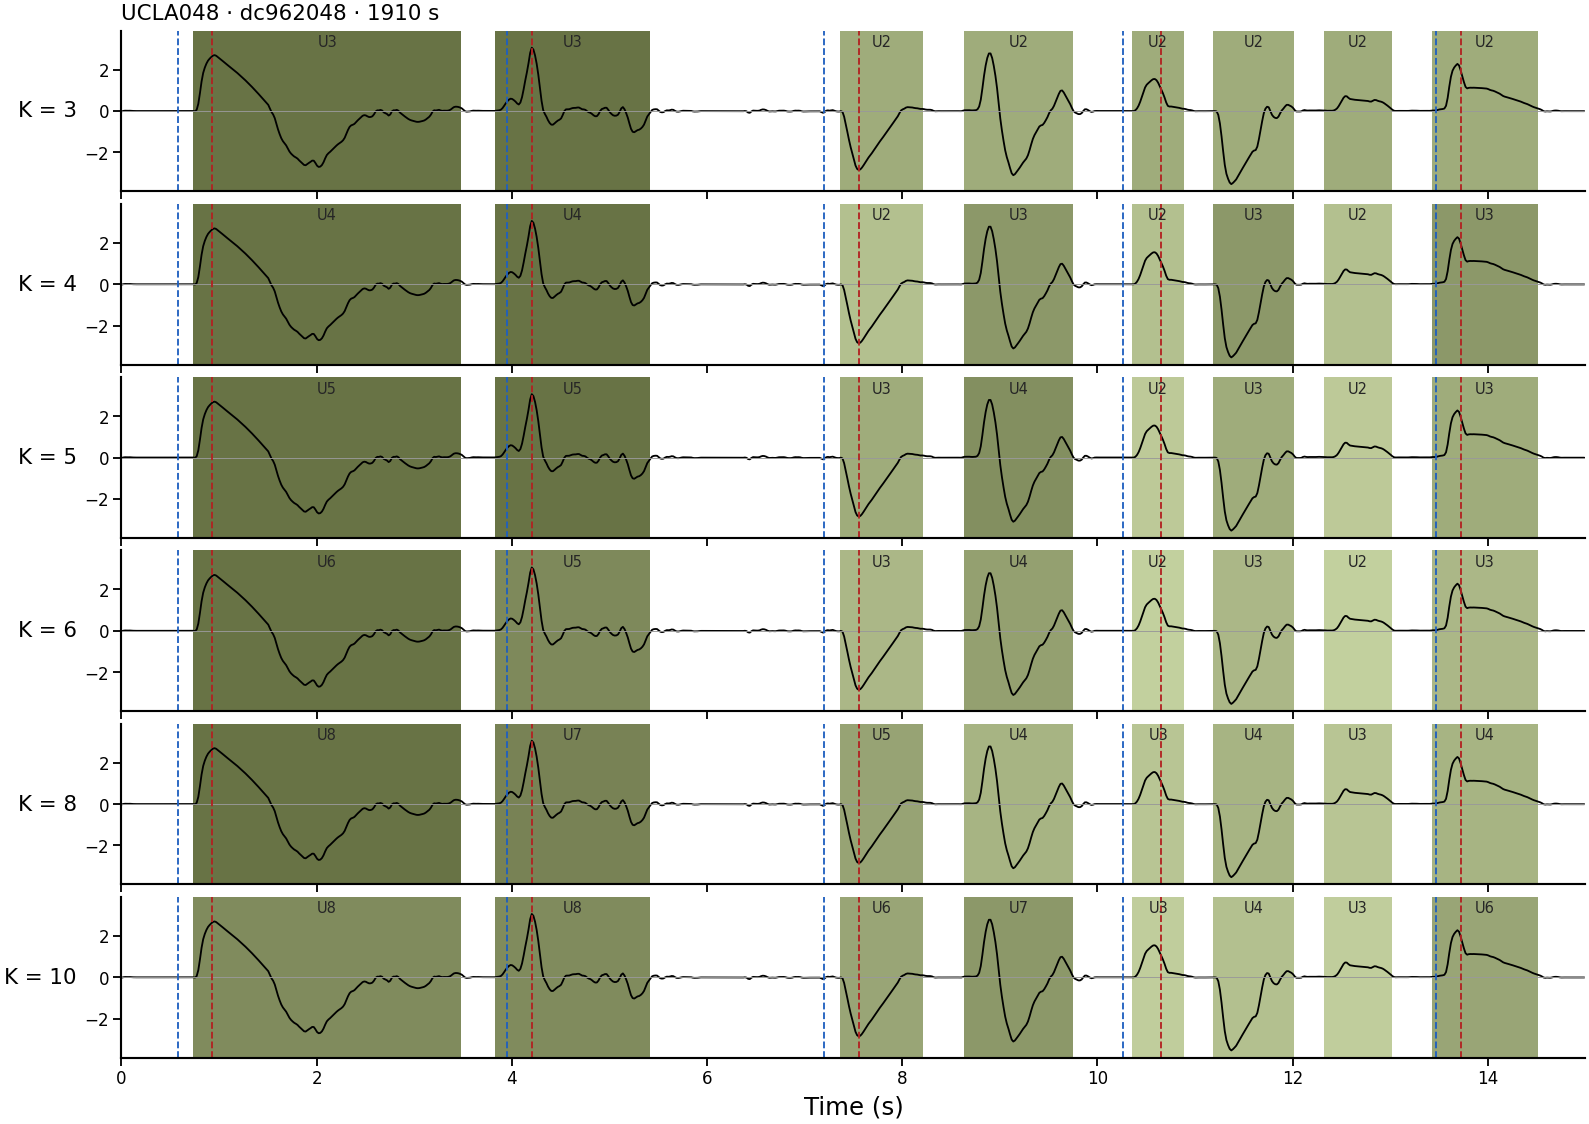

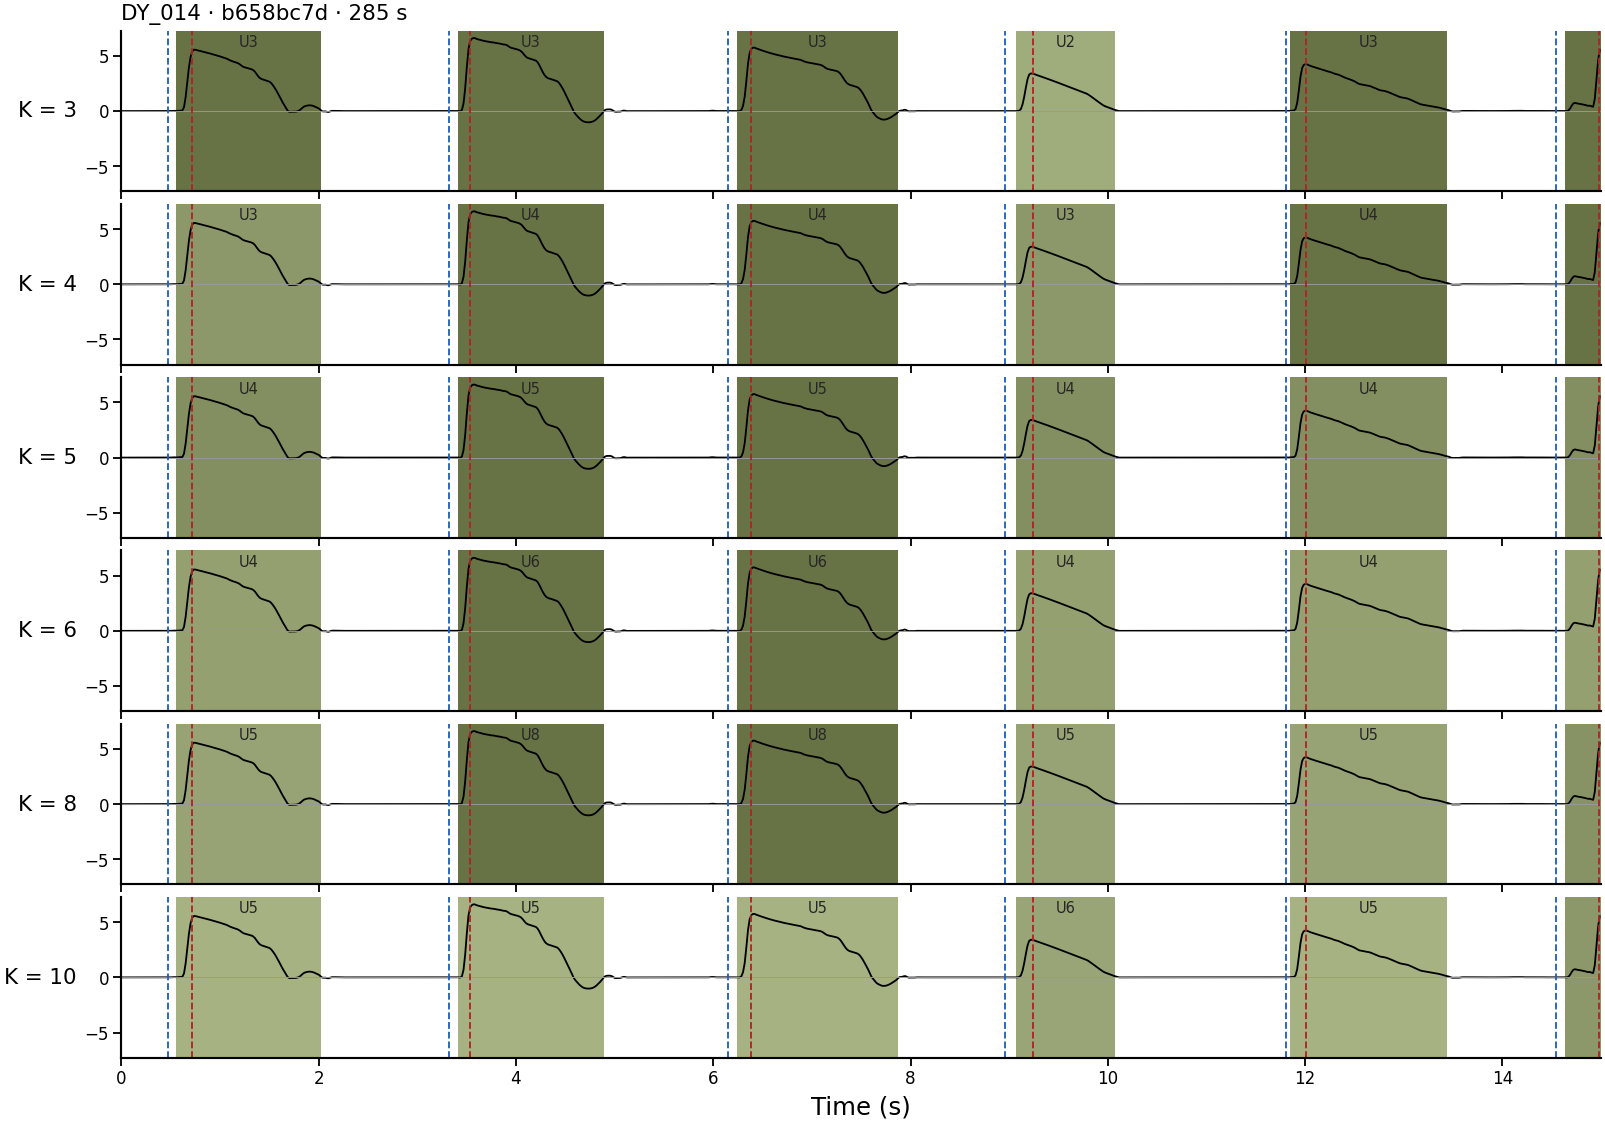

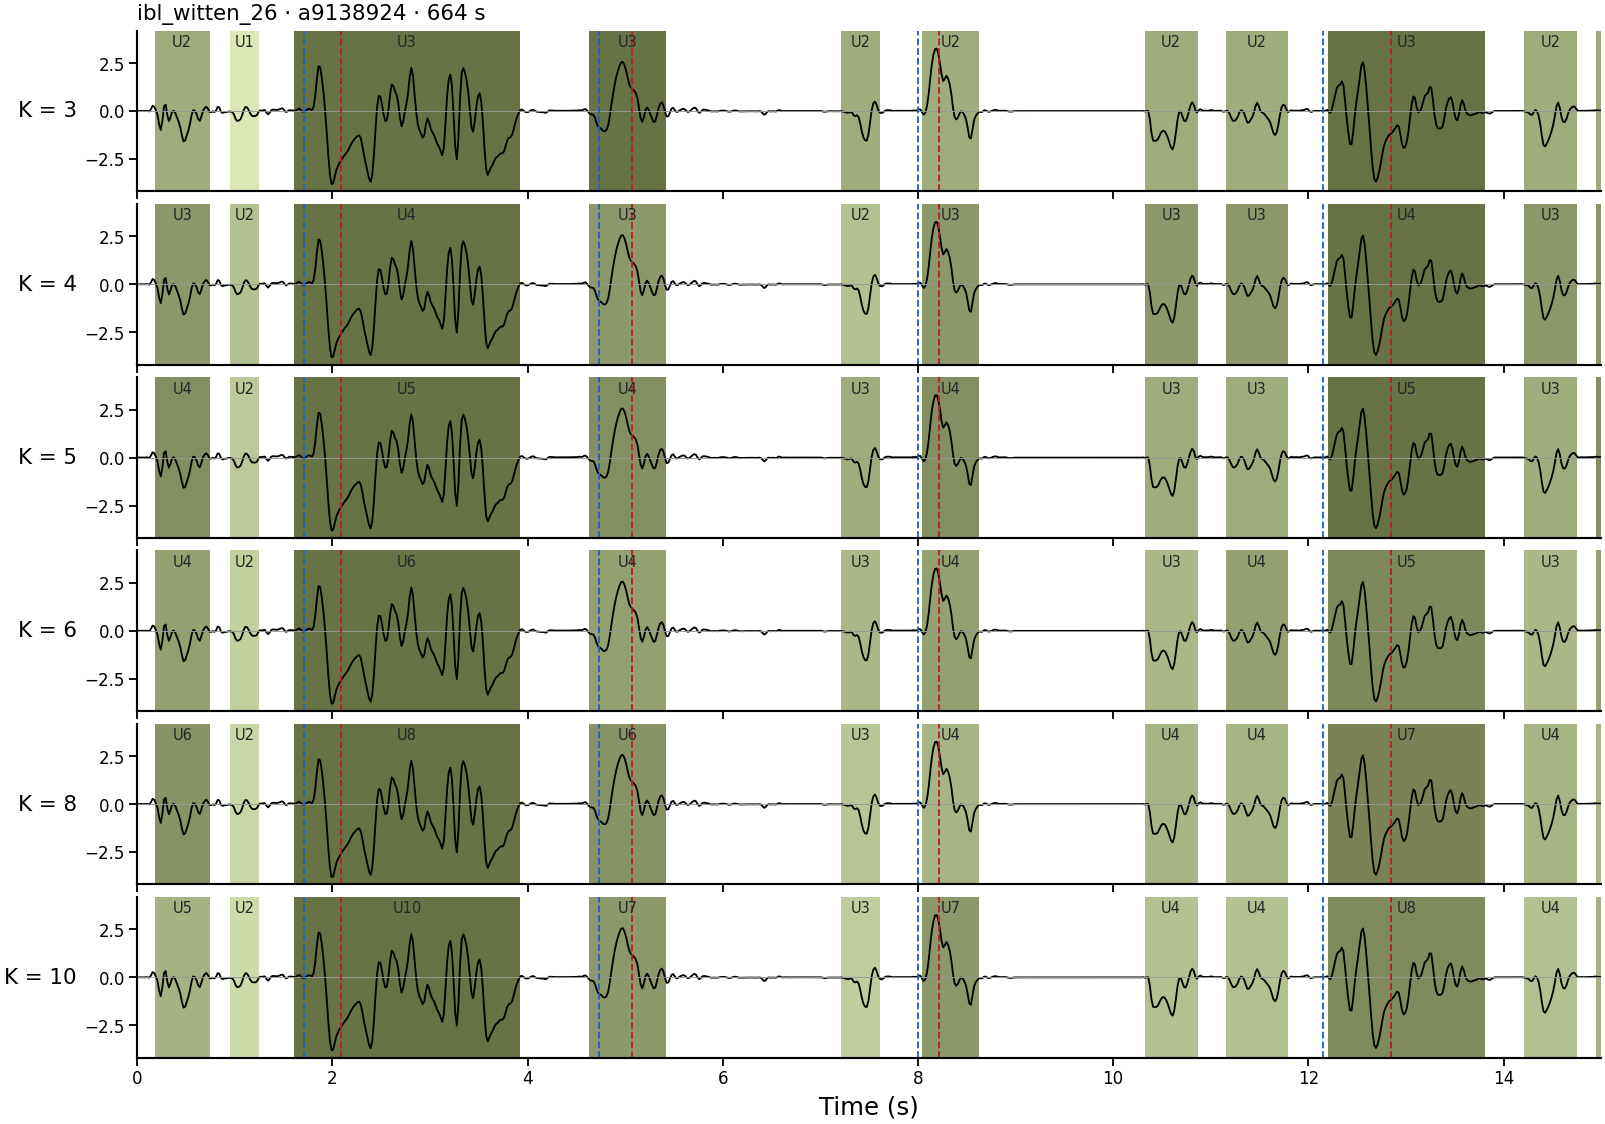

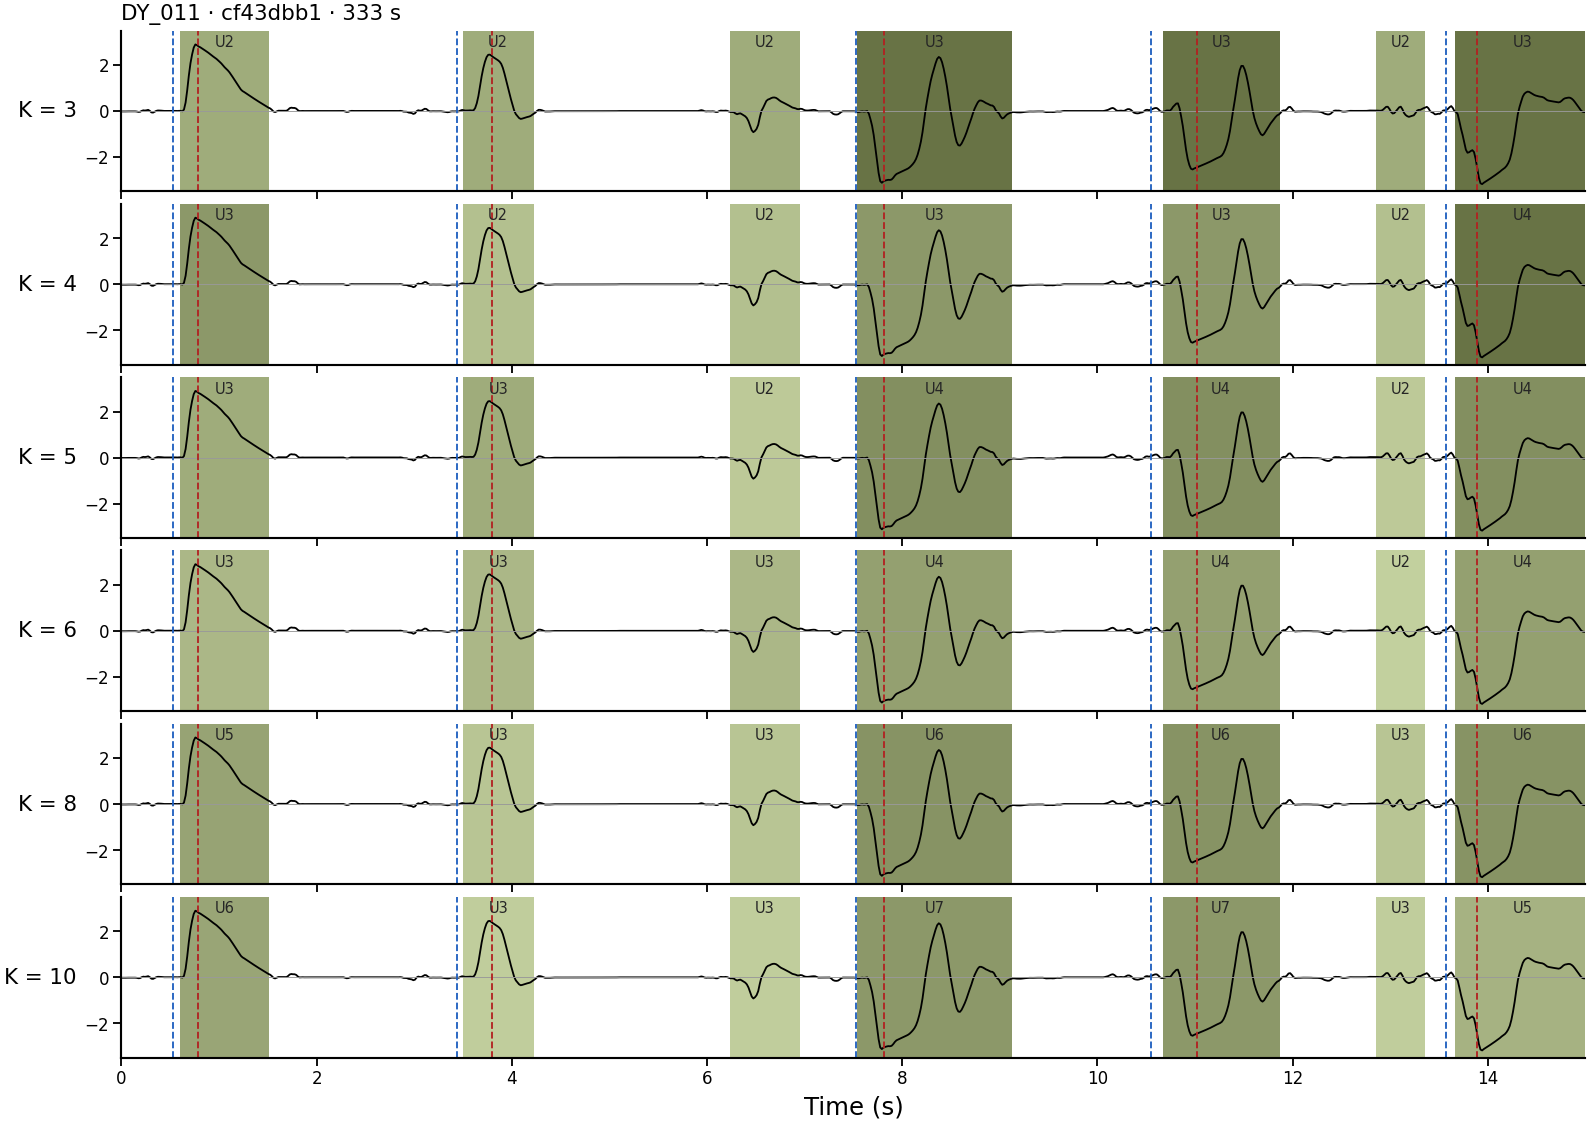

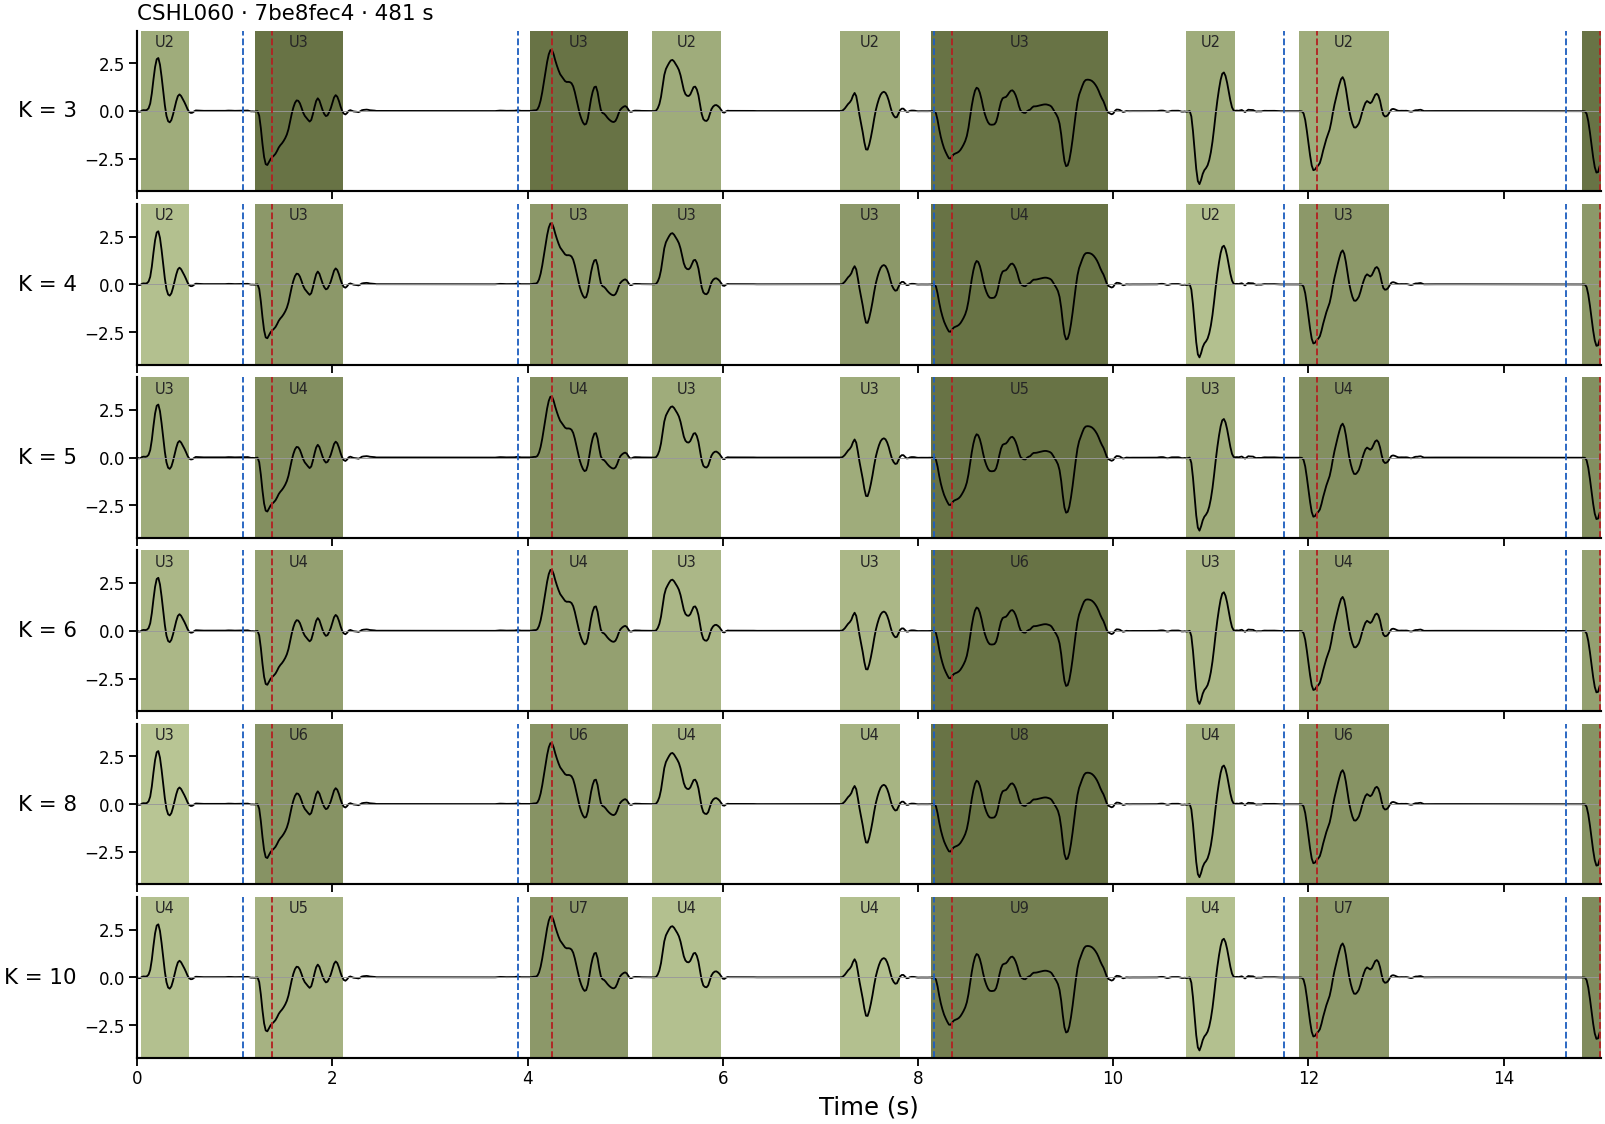

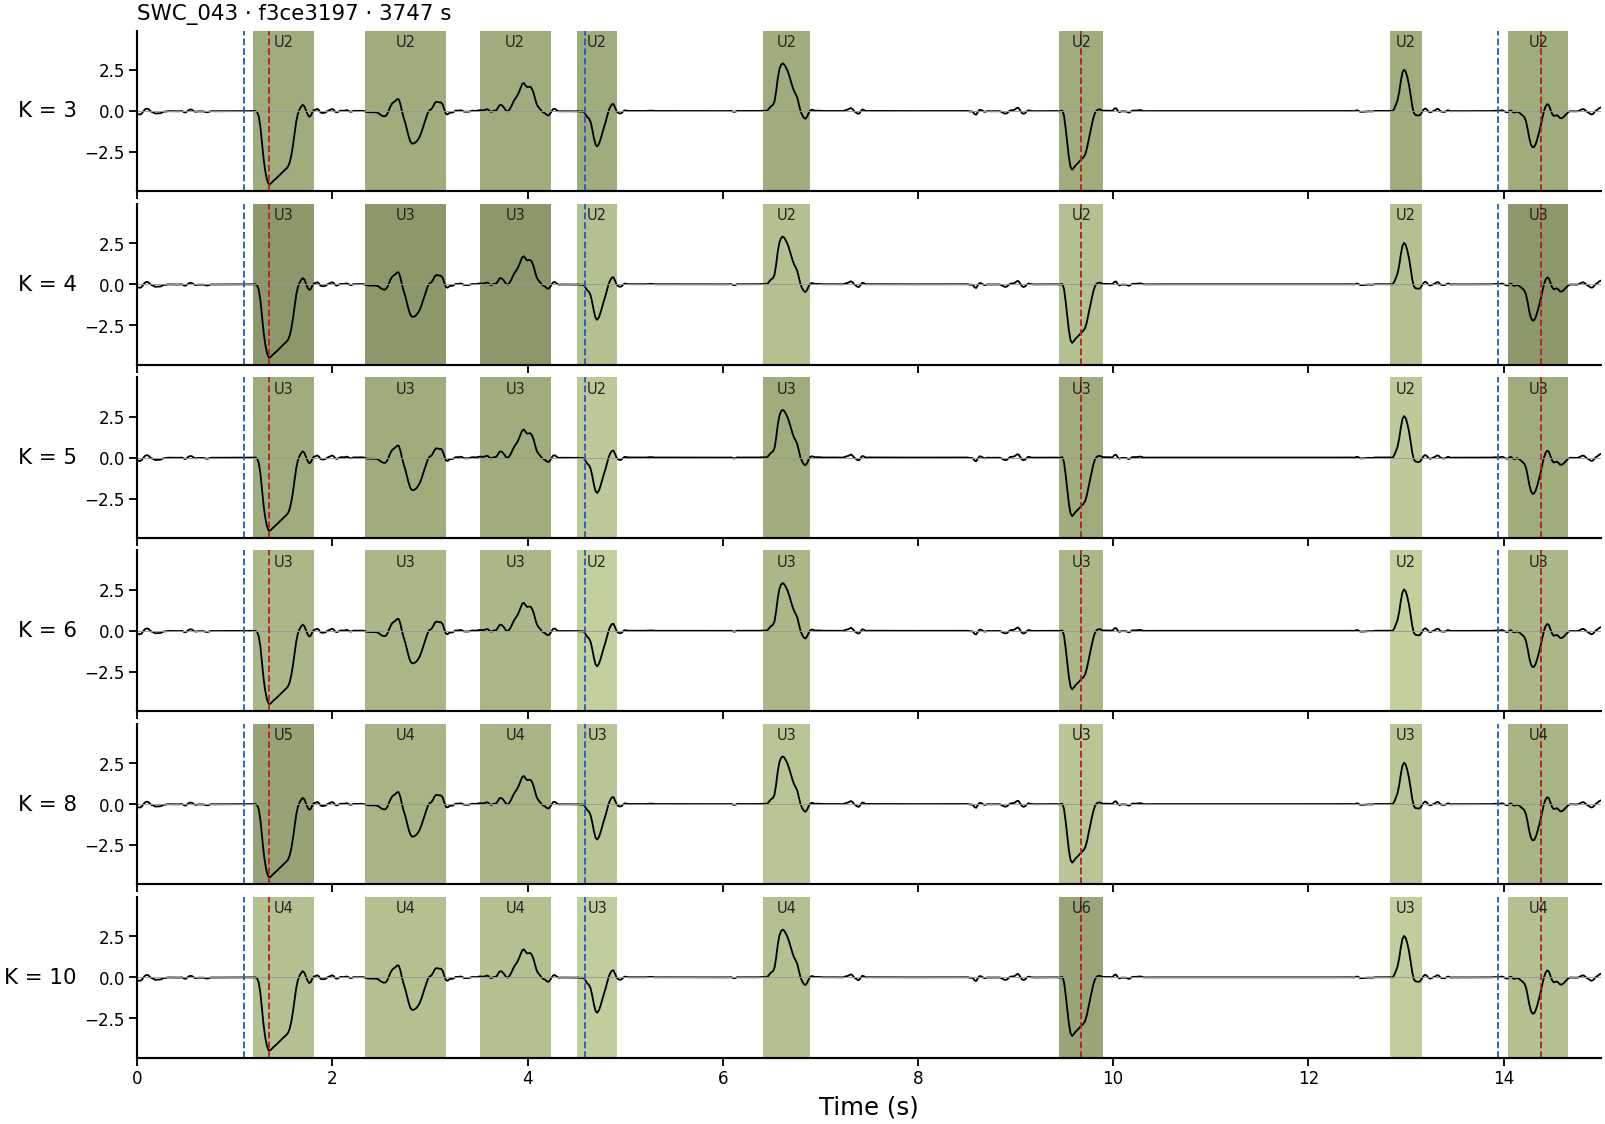

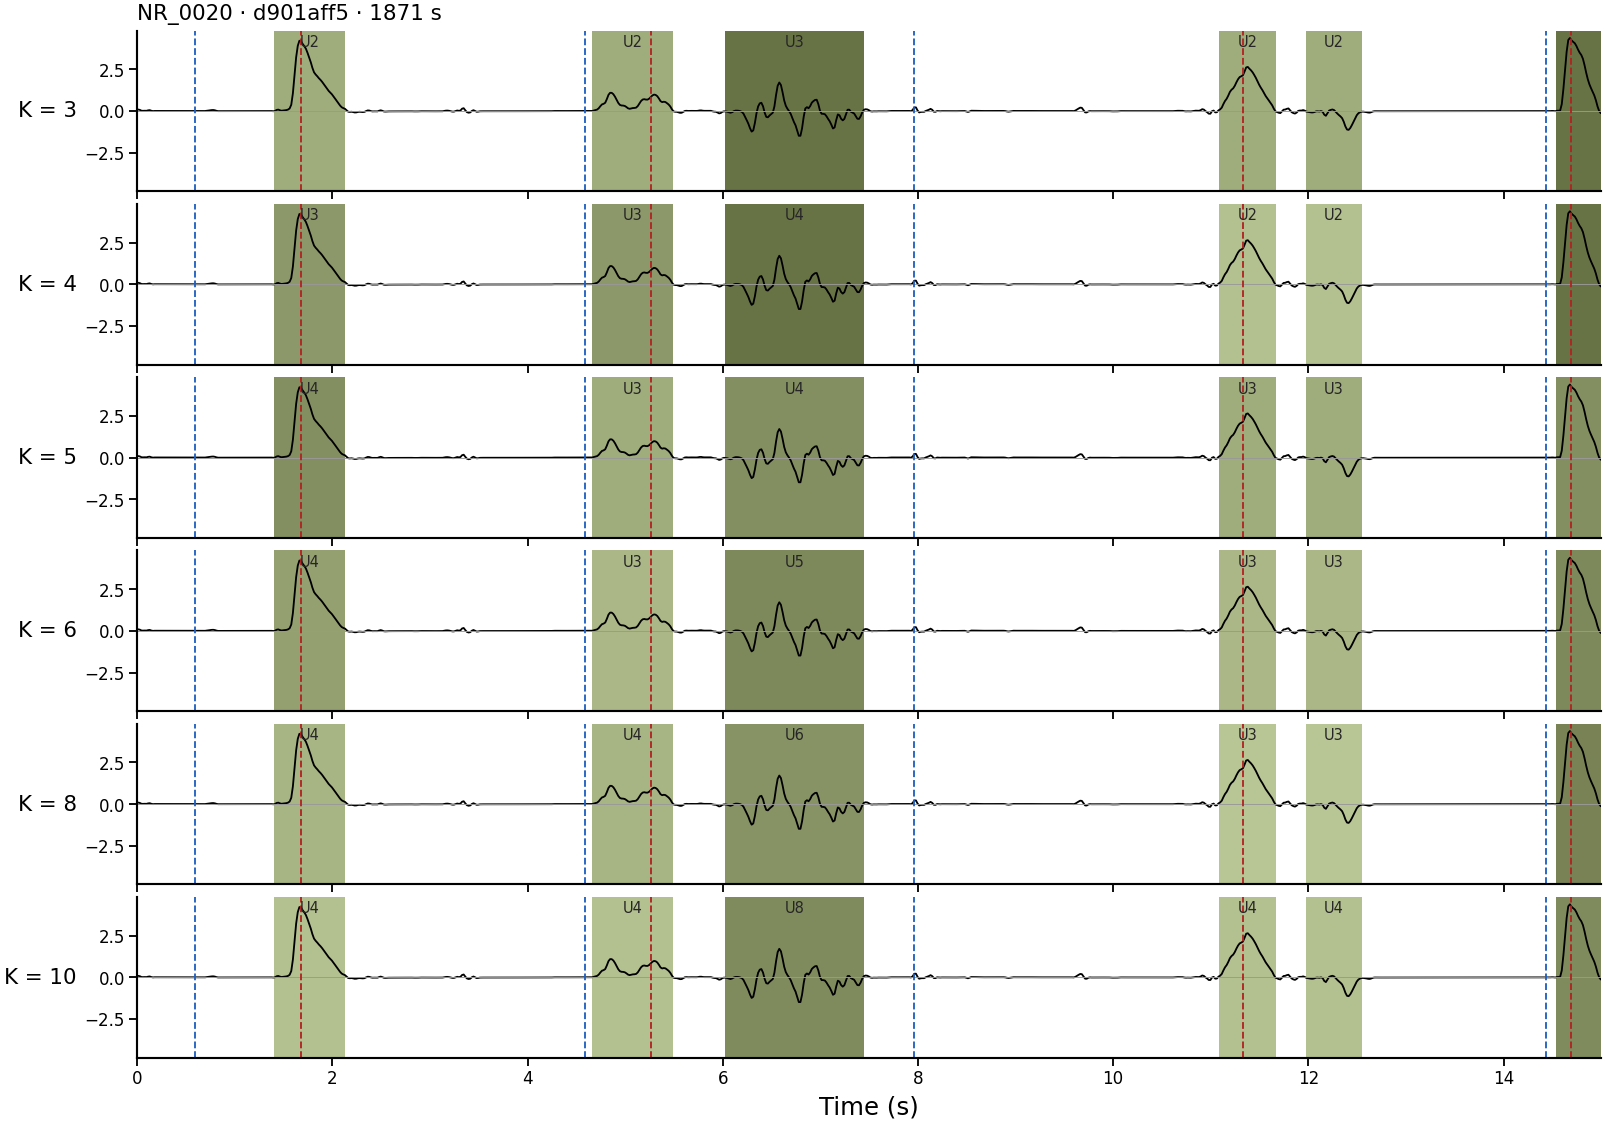

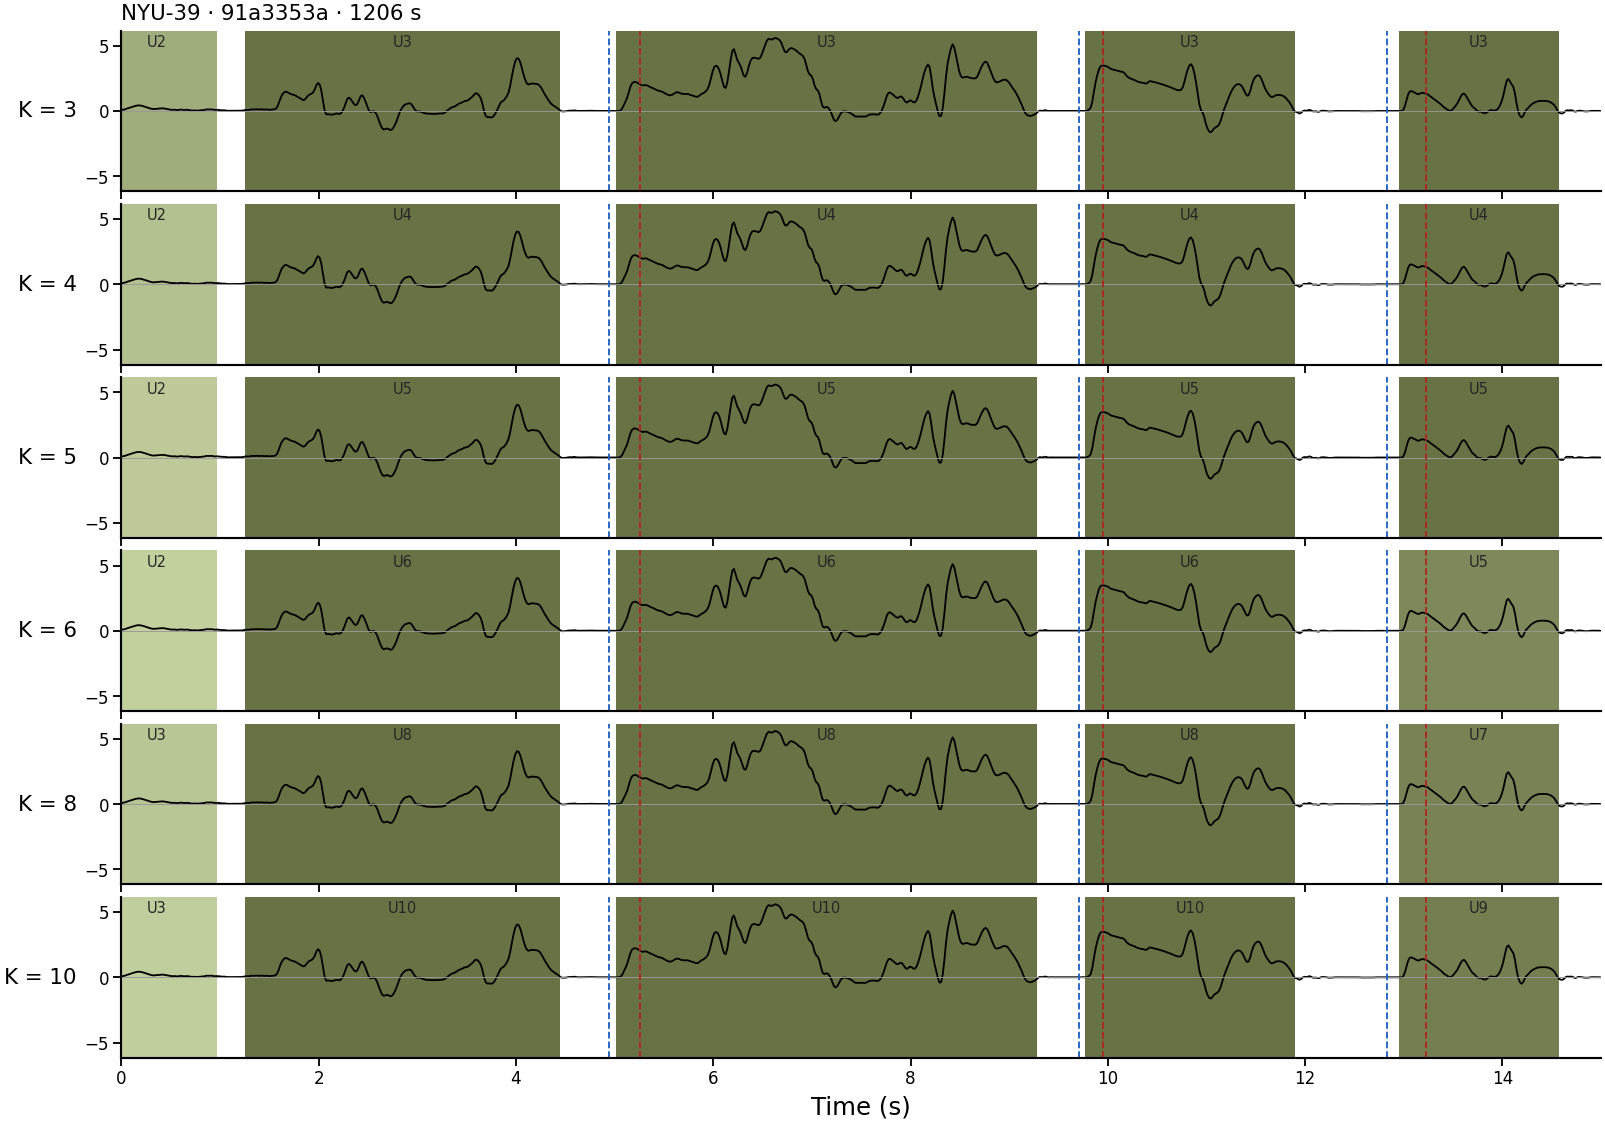

In [4]:
N_SESS, WIN = 8, 15.0
rng = np.random.default_rng(3)
picks = coh.groupby('mouse').sample(1, random_state=3).sample(N_SESS, random_state=3)
for m, e in zip(picks.mouse, picks.eid):
    t, v, iv, tr = wmc.load_session('proficient', m, e)
    Sx, ix = ALL_S[e], ALL_I[e]
    labs = {k: predict(k, Sx, ix.duration) for k in KS}
    starts = tr.intervals_0.values[(tr.intervals_0.values > ix.onset.min()) & (tr.intervals_0.values < ix.offset.max() - WIN)]
    t0 = rng.choice(starts)
    sel = (t >= t0) & (t <= t0 + WIN)
    w = np.flatnonzero((ix.offset.values >= t0) & (ix.onset.values <= t0 + WIN))
    lim = np.nanmax(np.abs(v[sel])) * 1.1
    fig, axs = plt.subplots(len(KS), 1, figsize=(7.5, 0.82 * len(KS) + 0.4), sharex=True)
    for ax, k in zip(axs, KS):
        for i in w:
            x0, x1 = ix.onset.values[i] - wmc.PAD_S - t0, ix.offset.values[i] + wmc.PAD_S - t0
            c = labs[k][i]
            ax.axvspan(x0, x1, color=COLS[k][c], lw=0, alpha=0.9)
            if x1 - x0 > 0.2 and 0 <= (x0 + x1) / 2 <= WIN:
                ax.text((x0 + x1) / 2, lim * 0.95, f'U{c + 1}', ha='center', va='top', fontsize=4.8, color='0.15')
        ax.plot(t[sel] - t0, v[sel], color='k', lw=0.6)
        ax.axhline(0, color='0.6', lw=0.3)
        for ev, col in (('stimOn_times', '#1f5fbf'), ('feedback_times', '#b22222')):
            for xx in tr[ev].values - t0:
                if 0 <= xx <= WIN:
                    ax.axvline(xx, color=col, lw=0.6, ls='--')
        ax.set(xlim=(0, WIN), ylim=(-lim, lim)); ax.tick_params(labelsize=5.5)
        ax.set_ylabel(f'K = {k}', fontsize=7, rotation=0, ha='right', va='center')
    axs[0].set_title(f'{m} · {e[:8]} · {t0:.0f} s', fontsize=7, loc='left')
    axs[-1].set_xlabel('Time (s)')
    plt.tight_layout(h_pad=0.2); plt.show()